# Final Assignment Example: Hotel Bookings

The dataset we are working with contains booking information for city hotels in Lisbon and resort hotels in Algarve (both in Portugal), provided by Hotel booking demand. Each row represents an individual reservation, and each column provides various details about the booking.

You can read more details about the dataset from [here](https://www.kaggle.com/datasets/mathsian/hotel-bookings).

First, we will load the necessary modules and data to run this notebook.

In [1]:
import copy, requests, io, zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
import lightgbm as lgb

pd.set_option('display.float_format', '{:.3f}'.format)



Next, we will download the dataset.

In [2]:
!curl -L -o hotel-bookings.zip https://www.kaggle.com/api/v1/datasets/download/mathsian/hotel-bookings

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0


In [3]:
# Specify the url with data
url = 'https://github.com/aaqibqadeer/Hotel-booking-demand/archive/refs/heads/master.zip'

# Acquire data from the url
r = requests.get(url, stream=True)

# read and extract the zipfile directly from memory
z = zipfile.ZipFile(io.BytesIO(r.content))
z.extractall()

# Rename the extracted folder contents if necessary to match 'hotel_bookings.csv'

In [4]:
# Correct the path to read the csv file from the extracted folder
df = pd.read_csv('Hotel-booking-demand-master/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,01-07-15
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,01-07-15
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,02-07-15
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,02-07-15
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,03-07-15


## 1.Background Organization and EDA (Exploratory Data Analysis)

In this notebook, we will focus primarily on the EDA part, while treating the market analysis as supplementary.

### 1-1.Market Analysis

The dataset contains accomodation data from Portugal for the years 2015 to 2017, but we will first assume the Japanese market to examine the market size and recent trends.

- Market Size of the Hotel Industry  (From the Teikoku Data Bank "Ryokan and Hotel Industry" Trend Report, 2022)
  - Approximately 3.4 trillion yen.
  - A 18.8% increase compared to FY2021.

  (Reference)2023 version：https://www.tdb.co.jp/report/industry/7cujz1u3cgju/


- Recent Trends and Issues for Lodgers  (from the Japan Tourism Agency Accomodation Travel Statistics Survey, 2023 (https://www.mlit.go.jp/kankocho/content/001751247.pdf))

  - Both Japanese and foreign lodgers have increased in number compared to 2022, when COVID-19 was still a concern.
  - Compared to 2019 (before COVID-19), the number of lodgers have slightly decreased.
  - The average room occupancy rate is 57%. There are significant variations by prefecture and hotel type.


### 1-2.EDA

In this section, we will perform a simple EDA (Exploratory Data Analysis) to understand the columns in the provided data.

First, we will take a look at the overview of the columns, their data type, missing values (if any), and other characteristics.

Below are the column descriptions:
- hotel: Type of hotel
- is_canceled: Whether the reservation was cancelled
- lead_time: Number of days between the reservation date and the stay date
- arrival_date_year: Arrival year
- arrival_date_month: Arrival month
- arrival_date_week_number: Week number of the arrival date
- arrival_date_day_of_month: Day of the month for the arrival date
- stays_in_weekend_nights: Number of weekend nights included in the stay
- stays_in_week_nights: Number of weekday nights included in a stay
- adults: Number of adults
- children: Number of children
- babies: Number of babies
- meal: Type of meal
- country: The country of the customer who made the reservation
- market_segment: The typep of reservation (e.g., travel agency, tour)
- distribution_channel: The channel through which the customer made the reservation
- is_repeated_guest: Whether the guest is a repeat customer
- previous_cancellations: Number of previous cancellations
- previous_bookings_not_canceled: umber of previous bookings that were not cancelled
- reserved_room_type: Type of room reserved
- assigned_room_type: Actual room type assigned to the guest
- booking_changes: Number of booking changes
- deposit_type: Type of deposit
- agent: ID of the agent who handled the booking
- company: ID of hte company that handled the booking
- days_in_waiting_list: Number of days on the waiting list
- customer_type: Type of customer
- adr: Average daily rate (amount paid per night)
- required_car_parking_spaces: Number of required parking spaces
- total_of_special_requests: Total number of special requests
- reservation_status: Reservation status
- reservation_status_date: Date when the reservation status was updated

In [5]:
print('The dataset contains {} records and {} variables.'.format(df.shape[0], df.shape[1]))

The dataset contains 119390 records and 32 variables.


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000,119390.000,119390.000,119390.000,119390.000,119390.000,119390.000,119390.000,119386.000,119390.000,119390.000,119390.000,119390.000,119390.000,103050.000,6797.000,119390.000,119390.000,119390.000,119390.000
mean,0.370,104.011,2016.157,27.165,15.798,0.928,2.500,1.856,0.104,0.008,0.032,0.087,0.137,0.221,86.693,189.267,2.321,101.831,0.063,0.571
std,0.483,106.863,0.707,13.605,8.781,0.999,1.908,0.579,0.399,0.097,0.176,0.844,1.497,0.652,110.775,131.655,17.595,50.536,0.245,0.793
min,0.000,0.000,2015.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,6.000,0.000,-6.380,0.000,0.000
25%,0.000,18.000,2016.000,16.000,8.000,0.000,1.000,2.000,0.000,0.000,0.000,0.000,0.000,0.000,9.000,62.000,0.000,69.290,0.000,0.000
50%,0.000,69.000,2016.000,28.000,16.000,1.000,2.000,2.000,0.000,0.000,0.000,0.000,0.000,0.000,14.000,179.000,0.000,94.575,0.000,0.000
75%,1.000,160.000,2017.000,38.000,23.000,2.000,3.000,2.000,0.000,0.000,0.000,0.000,0.000,0.000,229.000,270.000,0.000,126.000,0.000,1.000
max,1.000,737.000,2017.000,53.000,31.000,19.000,50.000,55.000,10.000,10.000,1.000,26.000,72.000,21.000,535.000,543.000,391.000,5400.000,8.000,5.000


In [8]:
null = pd.DataFrame({'Missing Values' : df.isna().sum(), 'Percentage of Missing Values' : (df.isna().sum()) / (df.shape[0]) * (100)})
null[null['Missing Values'] > 0]

,Missing Values,Percentage of Missing Values
children,4,0.003
country,488,0.409
agent,16340,13.686
company,112593,94.307


We can conclude the following:
- Number of records: 119390
- Number of columns: 32
- Missing values: 4 columns
- Categorical variables: 12
- Numerical variables: 20

Next, we will check the contents of the columns.

First, let's take a look at the count plot and histogram for numerical data.
From this, **we can observe that the cancellation rate seems relatively high, there are fewer children and babies, and there are not many repeating customers**.

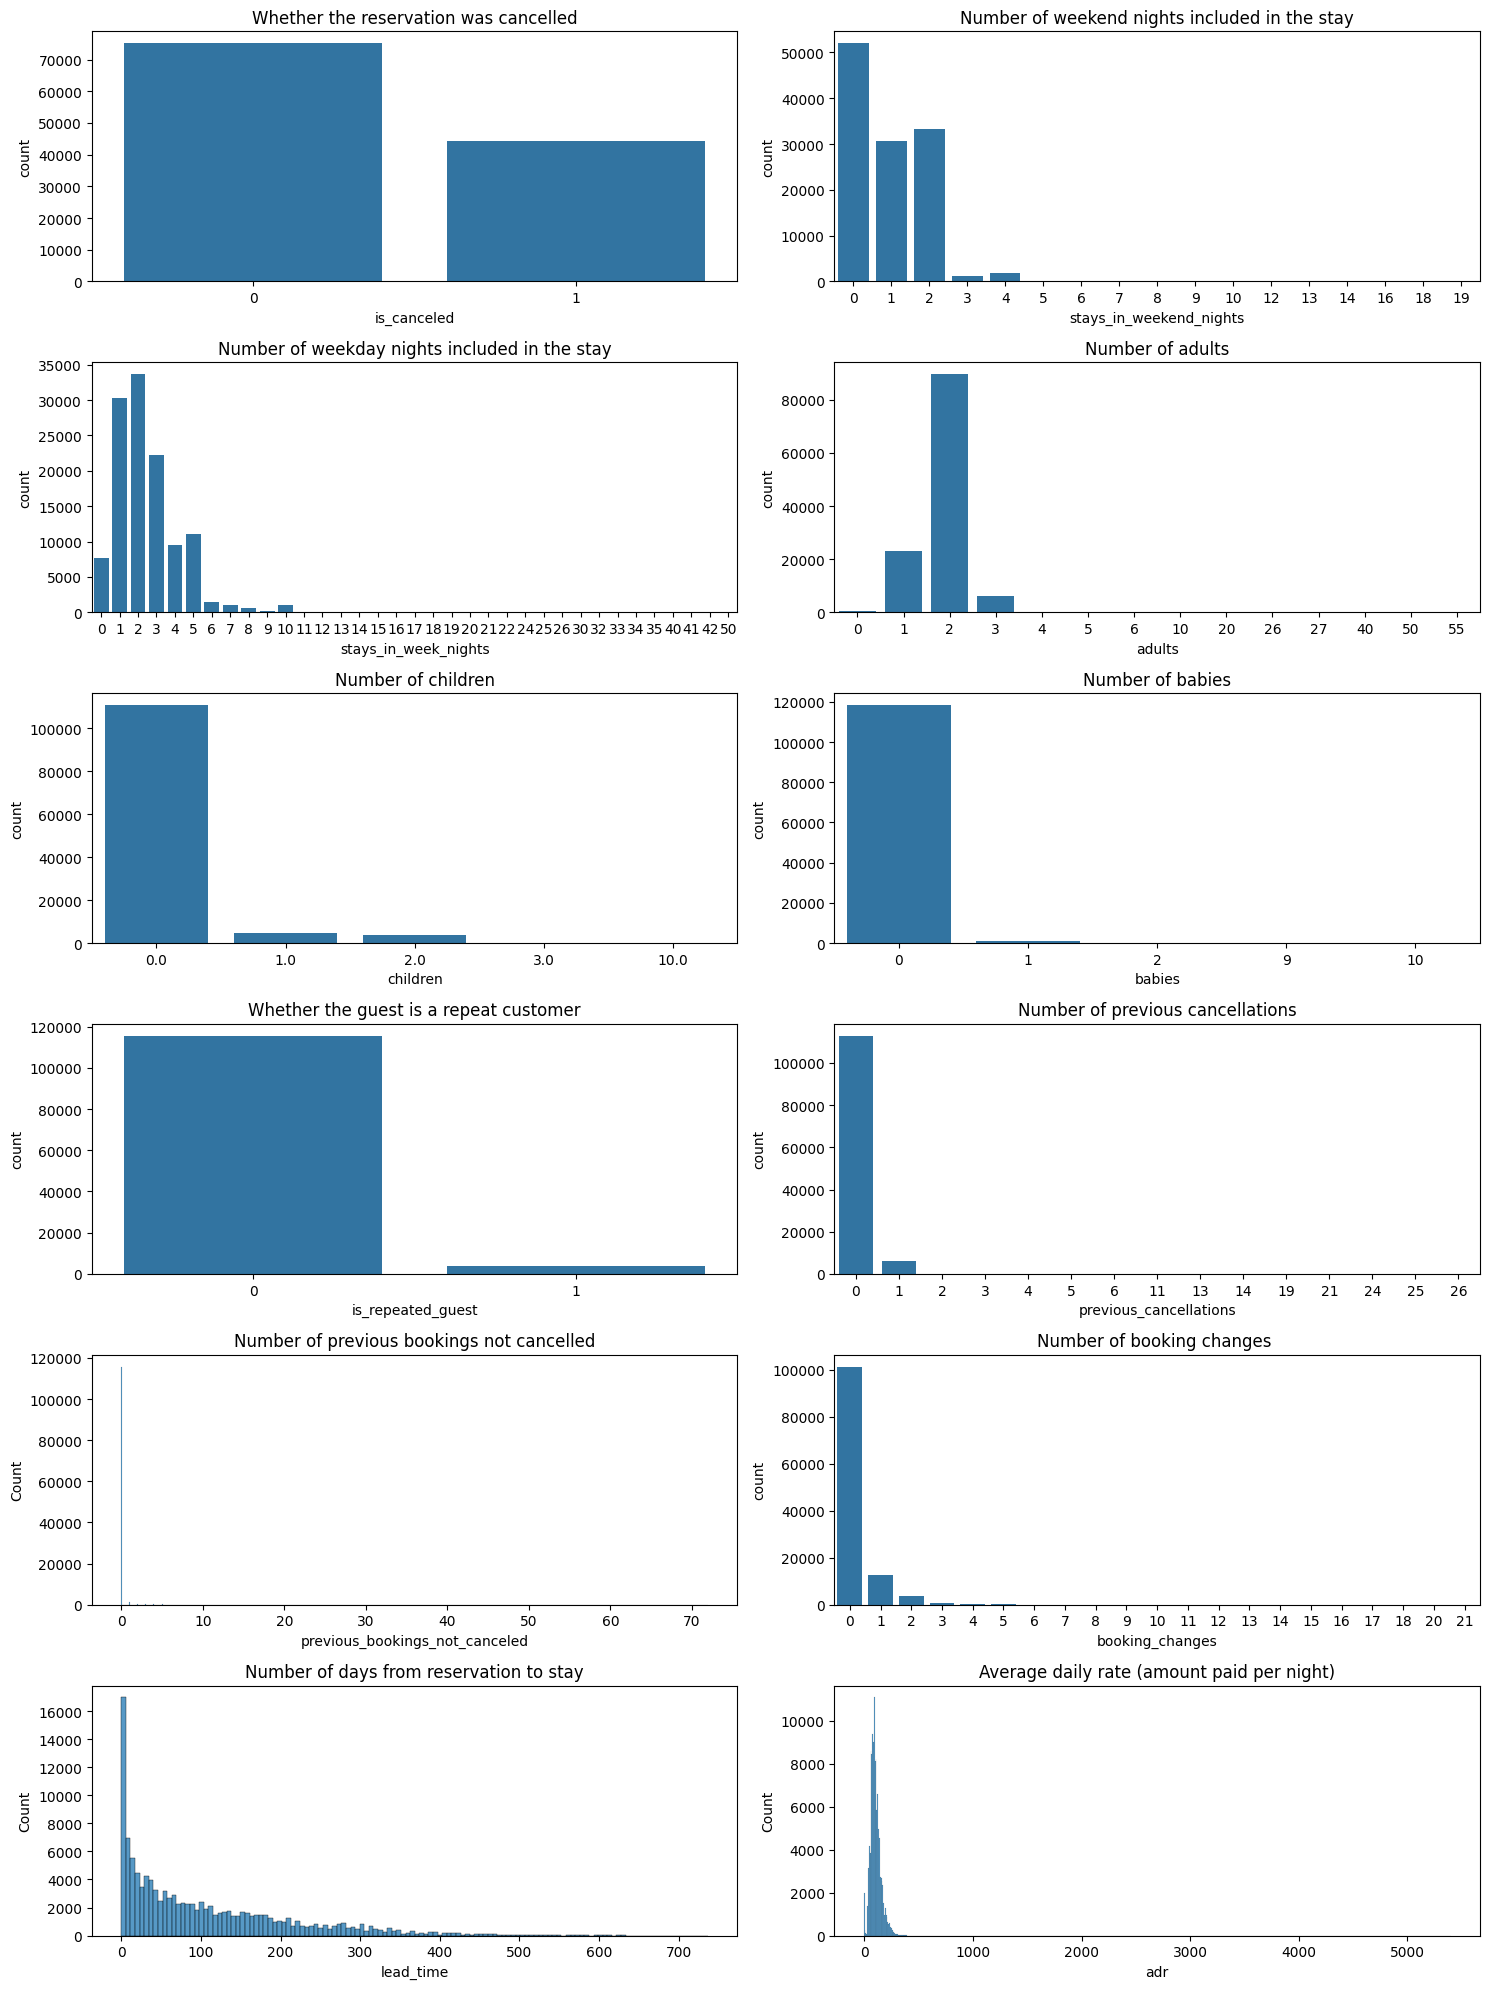

In [9]:
# Plot configurations
fig, axes = plt.subplots(6, 2, figsize=(15, 20))

# is_canceled
sns.countplot(x='is_canceled', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Whether the reservation was cancelled')

#stays_in_weekend_nights
sns.countplot(x='stays_in_weekend_nights', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Number of weekend nights included in the stay')

#stays_in_week_nights
sns.countplot(x='stays_in_week_nights', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Number of weekday nights included in the stay')

#adults
sns.countplot(x='adults', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Number of adults')

#children
sns.countplot(x='children', data=df, ax=axes[2, 0])
axes[2, 0].set_title('Number of children')

#babies
sns.countplot(x='babies', data=df, ax=axes[2, 1])
axes[2, 1].set_title('Number of babies')

#is_repeated_guest
sns.countplot(x='is_repeated_guest', data=df, ax=axes[3, 0])
axes[3, 0].set_title('Whether the guest is a repeat customer')

#previous_cancellations
sns.countplot(x='previous_cancellations', data=df, ax=axes[3, 1])
axes[3, 1].set_title('Number of previous cancellations')

#previous_bookings_not_canceled
sns.histplot(x='previous_bookings_not_canceled', data=df, ax=axes[4, 0])
axes[4, 0].set_title('Number of previous bookings not cancelled')

#booking_changes
sns.countplot(x='booking_changes', data=df, ax=axes[4, 1])
axes[4, 1].set_title('Number of booking changes ')

#lead_time
sns.histplot(x='lead_time', data=df, ax=axes[5, 0])
axes[5, 0].set_title('Number of days from reservation to stay')

#adr
sns.histplot(x='adr', data=df, ax=axes[5, 1])
axes[5, 1].set_title('Average daily rate (amount paid per night)')

plt.tight_layout()

Next, let's check the countplot for the categorical columns.

**We can see that city hotel reservations are common, customers come from many countries, and business-type rooms are reserved frequently**.

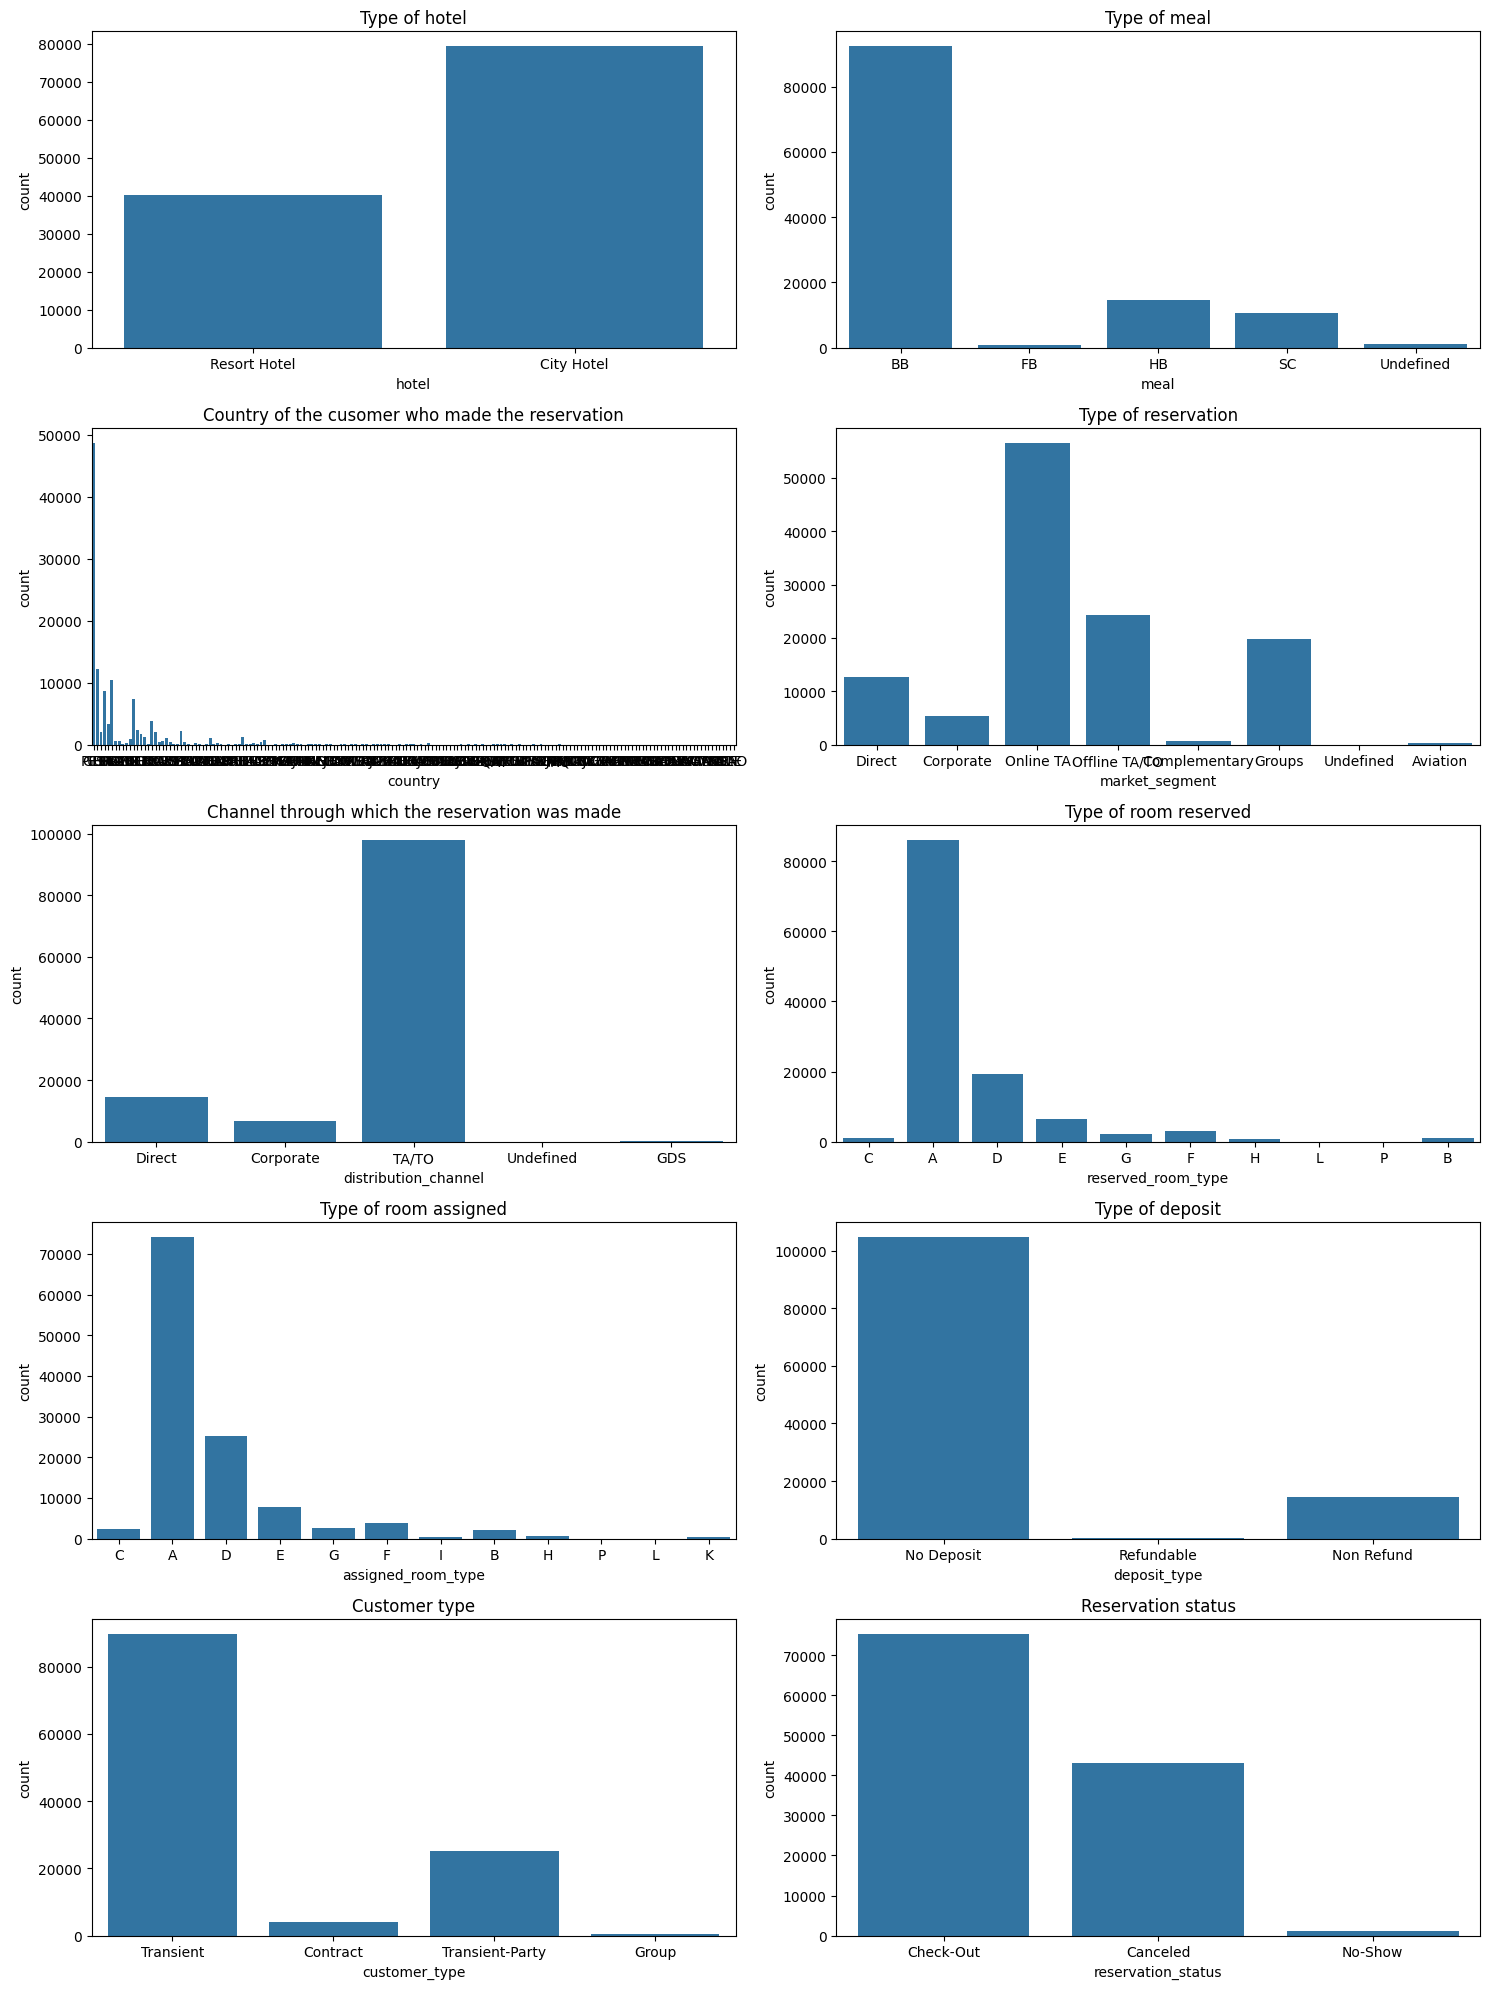

In [10]:
# Plot configurations
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

#hotel
sns.countplot(x='hotel', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Type of hotel')

#meal
sns.countplot(x='meal', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Type of meal')

#country
sns.countplot(x='country', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Country of the cusomer who made the reservation')

#market_segment
sns.countplot(x='market_segment', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Type of reservation')

#distribution_channel
sns.countplot(x='distribution_channel', data=df, ax=axes[2, 0])
axes[2, 0].set_title('Channel through which the reservation was made')

#reserved_room_type
sns.countplot(x='reserved_room_type', data=df, ax=axes[2, 1])
axes[2, 1].set_title('Type of room reserved')

#assigned_room_type
sns.countplot(x='assigned_room_type', data=df, ax=axes[3, 0])
axes[3, 0].set_title('Type of room assigned')

#deposit_type
sns.countplot(x='deposit_type', data=df, ax=axes[3, 1])
axes[3, 1].set_title('Type of deposit')

#customer_type
sns.countplot(x='customer_type', data=df, ax=axes[4, 0])
axes[4, 0].set_title('Customer type')

#reservation_status
sns.countplot(x='reservation_status', data=df, ax=axes[4, 1])
axes[4, 1].set_title('Reservation status')

plt.tight_layout()

The ```country``` column has too many unique values, making it hard to visualize. Therefore, we'll take a closer look at the content one by one.

In [11]:
df["country"].value_counts()

,count
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
...,...
MRT,1
KIR,1
SDN,1


Next, let's consider important metrics for evaluating services (potential target variables). For example, metrics like revenue or profit would make it easier to analyze from those columns. While we could move to market analysis at this point, let's think through columns for now.

From this EDA so far, a potential target variable could be ```is_canceled```. This variable indicates whether a reservation was cancelled or not. **By predicting cancellations, this could help with optimizing hotel reservation management and customer service**.

Other potential target variables include ```adr``` (average daily rate) and ```total_of_special_requests``` (total number of special requests). **These provide insights into customer payment tendencies and service requests, which could help optimize the hotel's business strategy and service offerings**.

We will check these three columns.

<Axes: title={'center': 'Whether a reservation was cancelled or not'}, ylabel='count'>

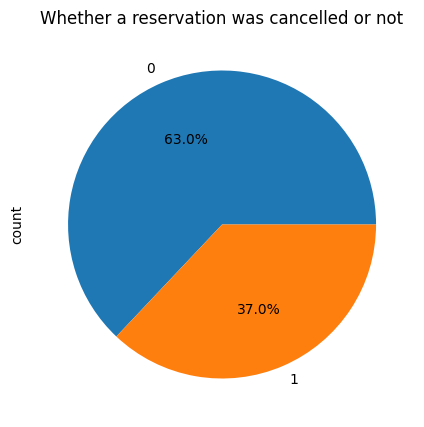

In [12]:
df["is_canceled"].value_counts().plot(kind="pie", autopct='%1.1f%%',title="Whether a reservation was cancelled or not", figsize=(5, 5))

The values of ```adr``` contain extreme values, which make the graph hard to read. Therefore, we will set plotting range of the ```adr``` values for better visualization.

<Axes: title={'center': 'Distribution of ADR (up to 500)'}, ylabel='Frequency'>

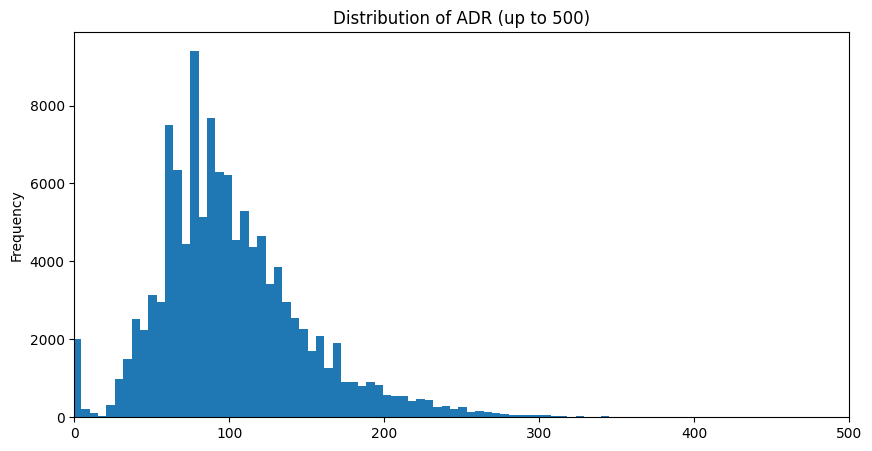

In [13]:
df["adr"].plot(kind="hist", bins=1000, figsize=(10, 5), title="Distribution of ADR (up to 500)", xlim=(0, 500))

<Axes: title={'center': 'Number of Special Requests'}, xlabel='total_of_special_requests'>

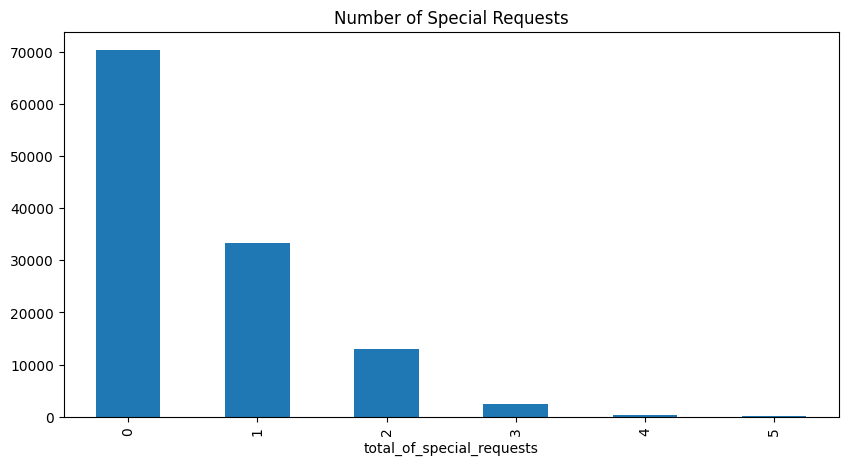

In [14]:
df["total_of_special_requests"].value_counts().plot(kind="bar", title="Number of Special Requests", figsize=(10, 5))


Looking at the three variables:
- ```is_canceled``` has a cancellation rate of around 40%.
- ```adr``` has a volume zone between 50 and 100, with some extreme values such as 0 and several thousands.
- ```total_of_special_requests``` is mostly concentrated around 0 and 1.

## 2.Hypothesis Formulation

Here, we will formulate a hypothecal problem based on the information obtained from the EDA so far. It's okay if the hypothesis is not very specific at this stage; by iterating through hypothesis formulation and verification, we aim to refine the problem definition.

Based on the recent EDA, the following problem hypotheses can be considered:
- High cancellation rate
- High/low average payment amount
- Inability to meet customer requests

In this notebook, we will consider that preventing cancellations would be most beneficial for the hotel, and proceed with the issue of "**High cancellation rate**".

## 3.Hypothesis Verification

### 3-1.Market Analysis

Here, we will refer to external data to check the cancellation rate in the hotel industry.

This data pertains to hotel bookings in Portugal. Therefore, we will use market data from D-Edge, which provides [cancellation rates from 680 hotels in Europe from 2014 to 2018](https://hospitalitytech.com/global-cancellation-rate-hotel-reservations-reaches-40-average), to investigate the cancellation rate.

![](https://assets1.hospitalitytech.com/images/v/max_width_741/2019-04/Capture-d%E2%80%99e%CC%81cran-2019-04-18-a%CC%80-18.50.16.png)

The article mentions that the trend of a global average of almost 40% cancellation rate "produces a very negative impact on hotel revenue and distribution management strategies". Additionally, the cancellation rate in the dataset analyzed is around the average cancellation rate, meaning there is a significant room for improvement.

Let's now propose a business plan aimed at improving the cancellation rate in the hotel industry.

### 3-2.EDA

#### 3-2-1. Relationship between cancellation rate and other columns

In this section, we will conduct a more detailed EDA by checking the correlation coefficients between ```is_canceled``` and other columns.

By identifying the factors most strongly related to cancellations, we will formulate specific business proposals.

In terms of the relationship between hotel type and the number of cancellations:
- City hotels have more cancellations
- City hotels have more bookings

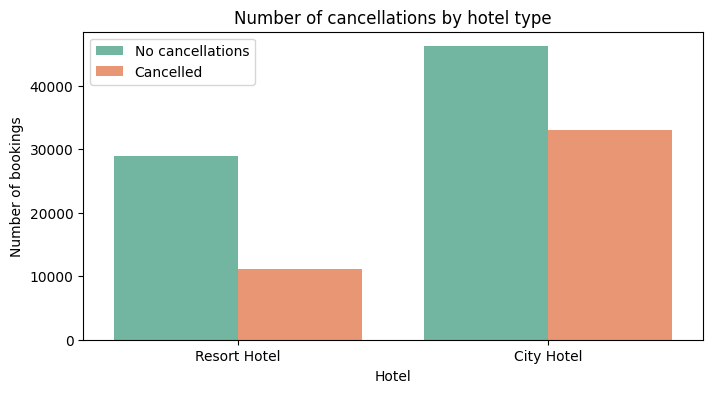

In [15]:
plt.figure(figsize=(8, 4))
ax1 = sns.countplot(x='hotel', hue='is_canceled', data=df, palette="Set2")
plt.title('Number of cancellations by hotel type')
plt.xlabel('Hotel')
plt.ylabel('Number of bookings')
plt.legend(['No cancellations', 'Cancelled'])
plt.show()

Columns with a large correlation coefficient are likely to be involved in cancellations. Let's check the three columns with the highest correlation coefficients.

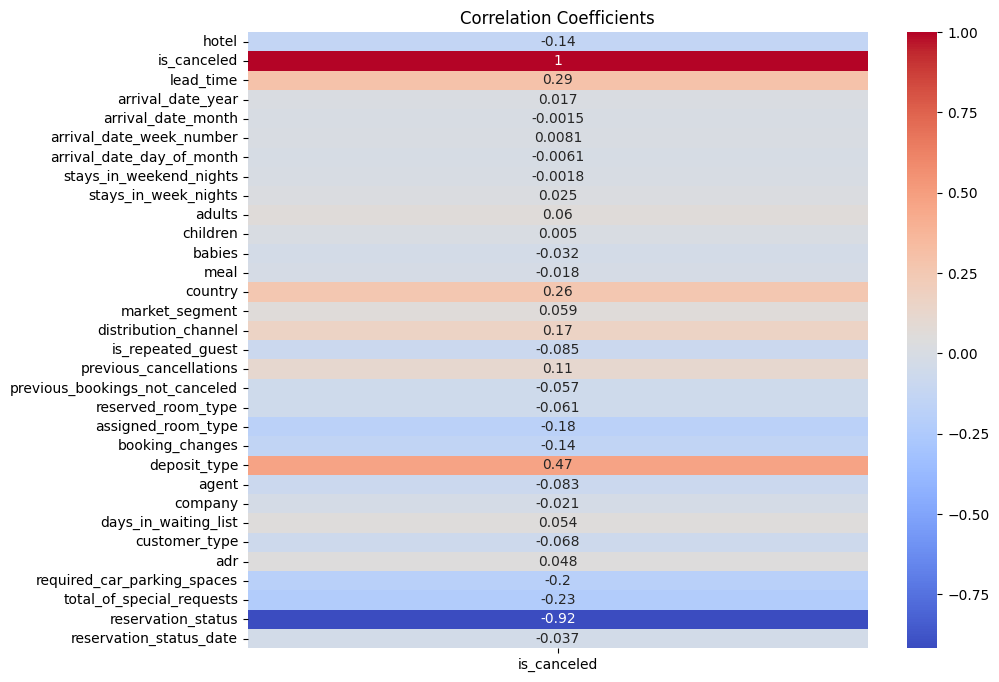

In [16]:
df_ = copy.deepcopy(df)
label_encoder = LabelEncoder()
object_columns = df.select_dtypes(include=['object']).columns
for column in object_columns:
    df_[column] = label_encoder.fit_transform(df[column])
corr_matrix = df_.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix[['is_canceled']], annot=True, cmap='coolwarm')
plt.title('Correlation Coefficients')
plt.show()

From the above, let's focus on `reservation_status`, `deposit_type`, and `lead_time`.

First, let's examine the relationship between `reservation_status` and cancellations.

In [17]:
print(df["reservation_status"].value_counts())
print(df[df["reservation_status"]=="Check-Out"]["is_canceled"].value_counts())
print(df[df["reservation_status"]=="Canceled"]["is_canceled"].value_counts())
print(df[df["reservation_status"]=="No-Show"]["is_canceled"].value_counts())

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64
is_canceled
0    75166
Name: count, dtype: int64
is_canceled
1    43017
Name: count, dtype: int64
is_canceled
1    1207
Name: count, dtype: int64


The ```reservation_status``` column, which has the highest correlation coefficient, represents whether the customer ultimately showed up as scheduled or not., It is likely this information is **not a factor** of cancellations, as it more of an outcome.

Next, let's visualize `deposit_type`.

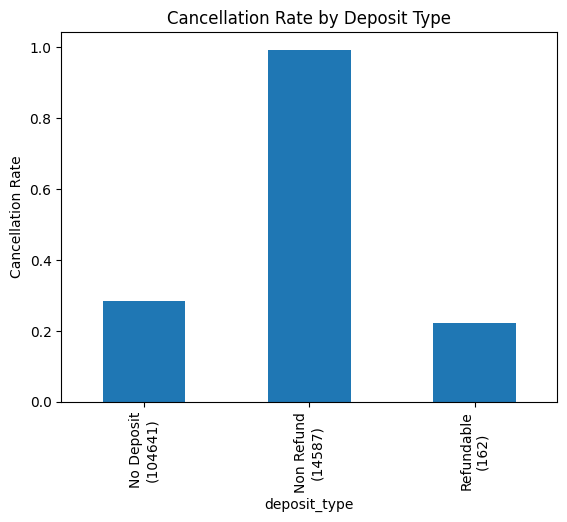

In [18]:
group_counts = df.groupby('deposit_type')['is_canceled'].count()
cancel_rates = df.groupby('deposit_type')['is_canceled'].mean()
fig, ax = plt.subplots()
cancel_rates.plot(kind='bar', ax=ax)
ax.set_xticklabels([f'{label}\n({count})' for label, count in zip(cancel_rates.index, group_counts)])

plt.title('Cancellation Rate by Deposit Type')
plt.ylabel('Cancellation Rate')
plt.show()

Looking at the descriptions of the elements of ```deposit_type```

* No Deposit - No deposit required.
* Non Refund  - Full accomodation cost required as a non-refundable deposit.
* Refundable  - A desposit smaller than the accomodation cost, refundable.

For this column, **despite being 'Non Refund' (non-refundable), the cancellation rate is very high**. Normally, if a cancellation fee is charged, one would expect customers to be more cautious when making a reservation.


Finally, let's visualize the relationship between `lead_time` and cancellation rate.

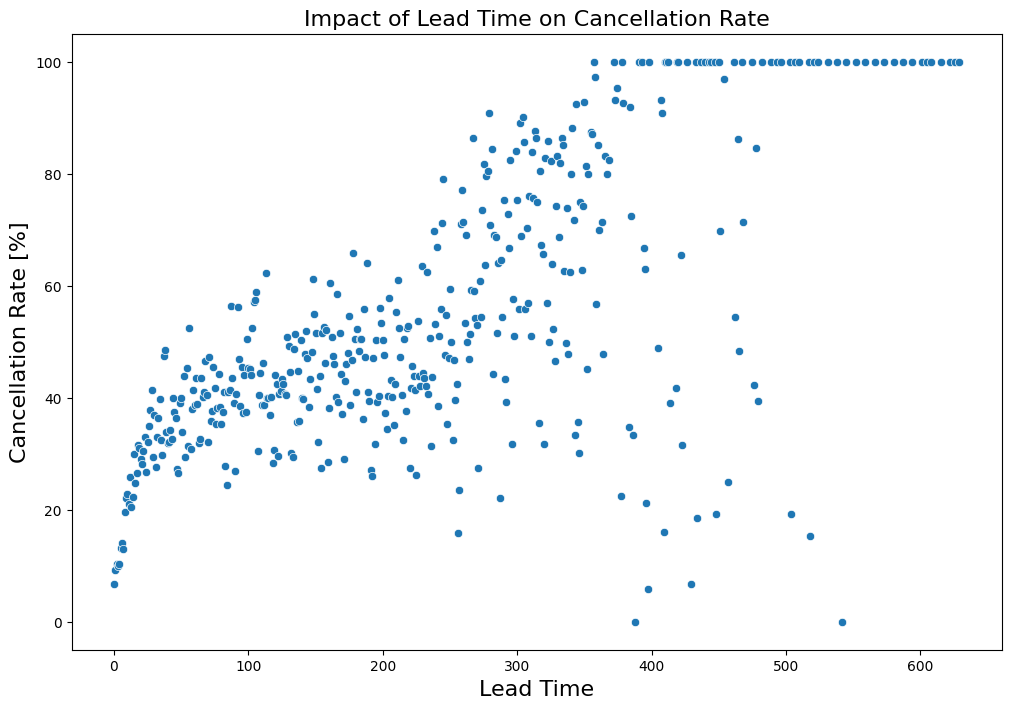

In [19]:
# Group data by lead_time：
lead_cancel_data = df.groupby("lead_time")["is_canceled"].describe()
# To avoid extreme values, create a graph using only lead_time with 10 or more reservations
lead_cancel_data_10 = lead_cancel_data.loc[lead_cancel_data["count"] >= 10]

plt.figure(figsize=(12, 8))
sns.scatterplot(x=lead_cancel_data_10.index, y=lead_cancel_data_10["mean"].values * 100)
plt.title("Impact of Lead Time on Cancellation Rate", fontsize=16)
plt.xlabel("Lead Time", fontsize=16)
plt.ylabel("Cancellation Rate [%]", fontsize=16)
plt.show()

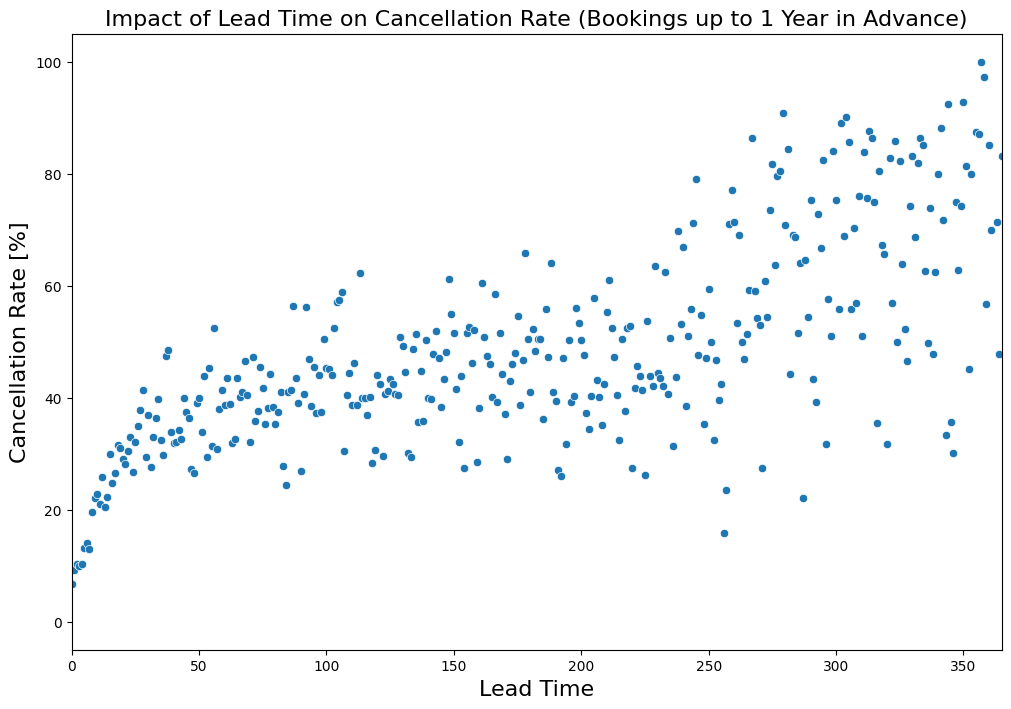

In [20]:
lead_cancel_data = df.groupby("lead_time")["is_canceled"].describe()
lead_cancel_data_10 = lead_cancel_data.loc[lead_cancel_data["count"] >= 10]

plt.figure(figsize=(12, 8))
sns.scatterplot(x=lead_cancel_data_10.index, y=lead_cancel_data_10["mean"].values * 100)
plt.title("Impact of Lead Time on Cancellation Rate (Bookings up to 1 Year in Advance)", fontsize=16)
plt.xlabel("Lead Time", fontsize=16)
plt.ylabel("Cancellation Rate [%]", fontsize=16)
plt.xlim(0,365)
plt.show()

**As the ```lead_time``` increases, there is a noticeable rise in the cancellation rate**.
Reducing the availability of future booking dates could potentially lower the cancellation rate.

By conducting a simple EDA, various insights regarding cancellations were gathered. Next, let's dive deeper into the inconsistencies in the ```deposit_type``` through further EDA.

#### 3-2-2. EDA on `deposit_type`

Here, we will examine the relationship between ```deposit_type``` and ```is_canceled``` more closely.

Consider possible situations where cancellations happen despite a "Non Redund" deposit. Some scenarios to consider might include:

1.   Weather or transportation disruptions: External factors such as bad weather or delayed transportation can lead to changes in travel plans.
2.   Changes in plans: Unexpected changes in scheduled events or meetings may require customers to adjust their dates.

While we cannot verify the first scenario with the current dataset, we can explore the second assumption by performing EDA.

Let's start by focusing on the rows with ```Non Refund``` deposit type and examining the correlation.

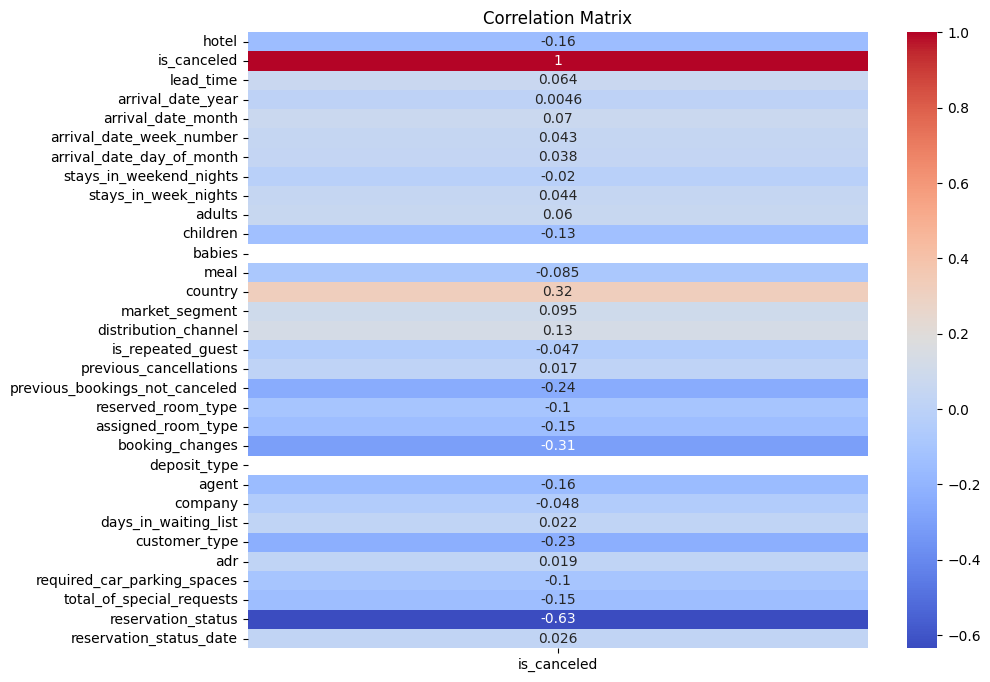

In [21]:
df_non_refund = df[df['deposit_type'] == 'Non Refund']
df_ = copy.deepcopy(df_non_refund)

label_encoder = LabelEncoder()
object_columns = df_non_refund.select_dtypes(include=['object']).columns
for column in object_columns:
    df_[column] = label_encoder.fit_transform(df_non_refund[column])
non_refund_corr_matrix = df_.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(non_refund_corr_matrix[['is_canceled']], annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [22]:
delta_corr = non_refund_corr_matrix['is_canceled'] - corr_matrix['is_canceled']
delta_corr = delta_corr.dropna()
delta_corr.sort_values(ascending=True)

,is_canceled
lead_time,-0.229
previous_bookings_not_canceled,-0.184
booking_changes,-0.163
customer_type,-0.160
children,-0.138
previous_cancellations,-0.094
agent,-0.078
meal,-0.068
reserved_room_type,-0.040
distribution_channel,-0.039


The four variables that show significant changes between the overall dataset and the subset with ```Non Refund``` deposit type are:

- ```children```

- ```customer_type```

- ```booking_changes```

- ```lead_time```

Now, let's focus on these four columns and explore them in more detail.

In [23]:
# Customer type
df["kids"] = df["children"] + df["babies"]
df_non_refund = df[df['deposit_type'] == 'Non Refund']
df_not_non_refund = df[df['deposit_type'] != 'Non Refund']

Let's first check the customer type.
The elements of the ```customer_type``` column are as follows:

* Contract - Associated with other bookings

* Group - Associated with a group booking

* Transient - Not associated with any booking

* Transient-party - Not a group, but associated with another individual booking

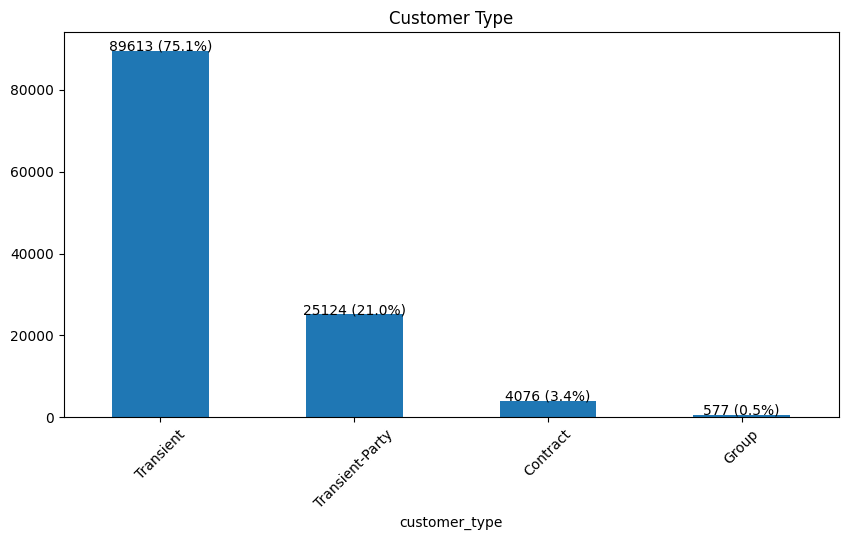

In [24]:
ax = df["customer_type"].value_counts().plot(kind="bar", title="Customer Type", figsize=(10, 5))
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
for i, v in enumerate(df["customer_type"].value_counts()):
    ax.text(i, v + 0.1, f"{v} ({v / len(df) * 100:.1f}%)", ha="center")

The proportion of "Transient" is quite high, while group bookings are almost nonexistent.

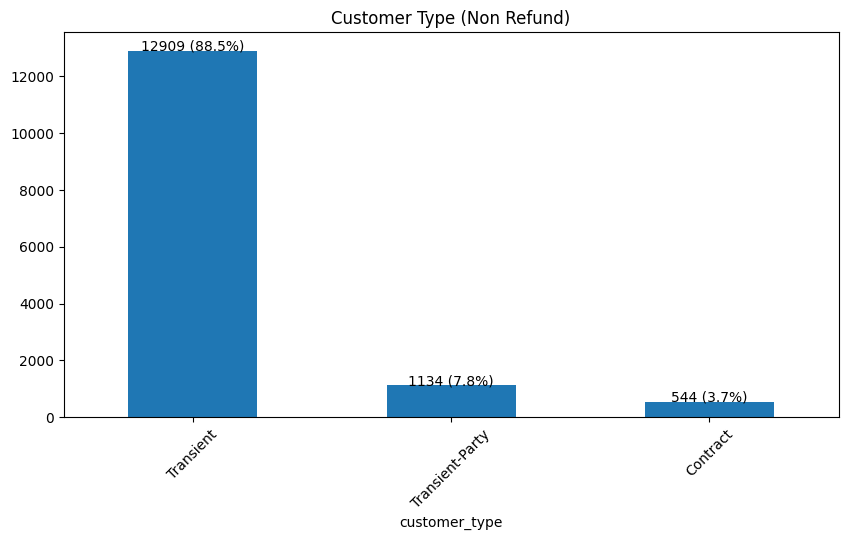

In [25]:
ax = df_non_refund["customer_type"].value_counts().plot(kind="bar", title="Customer Type (Non Refund)", figsize=(10, 5))
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
for i, v in enumerate(df_non_refund["customer_type"].value_counts()):
    ax.text(i, v + 0.1, f"{v} ({v / len(df_non_refund) * 100:.1f}%)", ha="center")

We can see that the **trend is similar for customers with "Non Refund"**.

Next, let's check the number of children.

In [26]:
print("Average number of children in the entire dateset: " + f"{df['kids'].mean():.3f}")
print("Average number of children in Non Refund data: " + f"{df_non_refund['kids'].mean():.3f}")

Average number of children in the entire dateset: 0.112
Average number of children in Non Refund data: 0.001


In [27]:
print("Average number of adults in the entire dataset: " + f"{df['adults'].mean():.3f}")
print("Average number of adults in Non Refund data: " + f"{df_non_refund['adults'].mean():.3f}")

Average number of adults in the entire dataset: 1.856
Average number of adults in Non Refund data: 1.811


By comparing the entire dataset and the Non Refund data, the average number of adults per reservation doesn't seem to change much, but **there is a large difference in the average number of children per reservation**.

It seems likely that there are fewer family groups in the Non Refund category.

Now, let's look at the `reserved_room_type`.

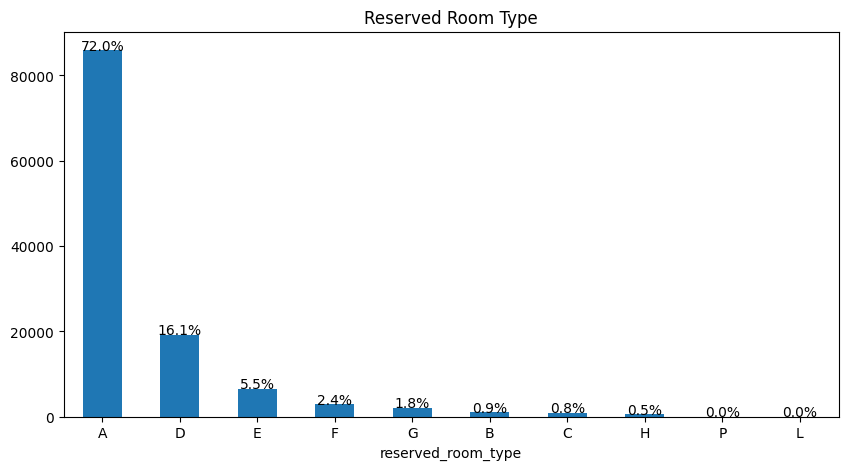

In [28]:
ax = df["reserved_room_type"].value_counts().plot(kind="bar", title="Reserved Room Type", figsize=(10, 5))
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(df["reserved_room_type"].value_counts()):
    ax.text(i, v + 0.1, f"{v / len(df) * 100:.1f}%", ha="center")

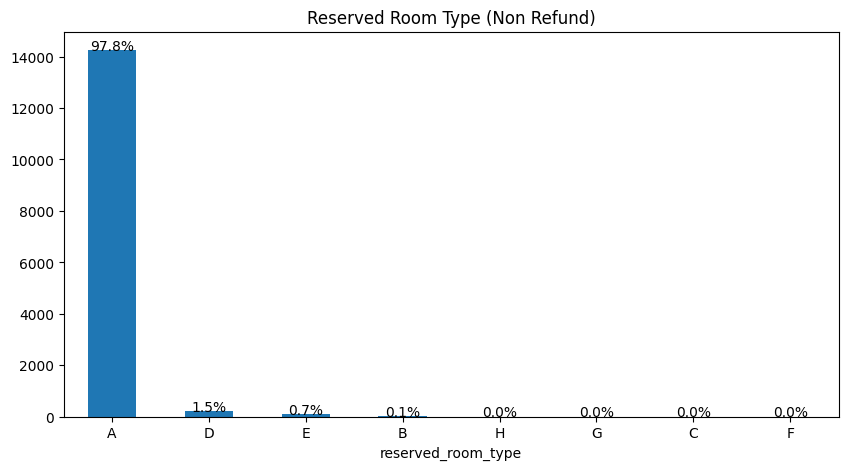

In [29]:
ax = df_non_refund["reserved_room_type"].value_counts().plot(kind="bar", title="Reserved Room Type (Non Refund)", figsize=(10, 5))
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(df_non_refund["reserved_room_type"].value_counts()):
    ax.text(i, v + 0.1, f"{v / len(df_non_refund) * 100:.1f}%", ha="center")

It seems that most of the ```room_type``` are Business.
Since there are few families and the room type is Business, **it is likely that business people are making hotel reservations and then canceling them**.

Finally, let's look at the `lead_time`.

There doesn't seem to be any extreme bias in the distribution of ```lead_time```. However, it can be observed that last-minute booking are few, and most of the bookings are made well in advance.

<Axes: title={'center': 'Lead Time Distribution (Non Refund)'}, ylabel='Frequency'>

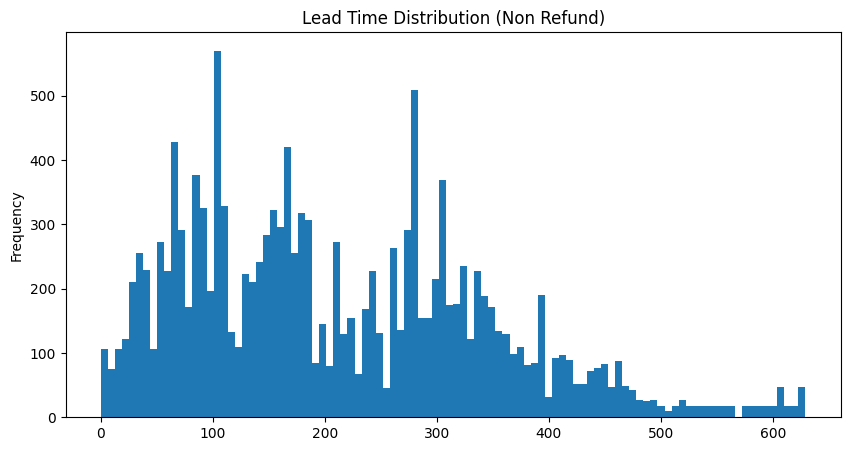

In [30]:
df_non_refund["lead_time"].plot(kind="hist", bins=100, figsize=(10, 5), title="Lead Time Distribution (Non Refund)")

In [31]:
df_lead = pd.DataFrame()
df_lead["ALL"] = df["lead_time"].describe()
df_lead["NON REFUND"] = df_non_refund["lead_time"].describe()
df_lead

,ALL,NON REFUND
count,119390.000,14587.000
mean,104.011,212.909
std,106.863,133.324
min,0.000,0.000
25%,18.000,103.000
50%,69.000,183.000
75%,160.000,304.000
max,737.000,629.000


After conducting this exploratory data analysis (EDA), the following points have been observed:
- The customer type is not group-related.
- There are few family groups among the customers.
- The room type is predominantly business-oriented.
- Reservations are being made much earlier than usual.

Based on this information, it can be inferred that business travelers are likely the primary customer group. The absence of group bookings and the low number of family groups suggest that individual or business-related trips are more common. Additionally, the predominance of business-oriented room types further supports the idea that accomodations are increasingly being booked for business purposes. Moreover, the fact that reservations are being made much earlier than usual implies that these trips are likely for planned business events or meetings.

Here are some potential solutions based on the analysis:

- Limit company bookings to allow reservations only at the last minute.
- Implement cancellation fees for business travelers who previously did not incur such fees.

However, these measures might not be realistic or could be difficult to assess quantitatively. While they can be considered as options, it might be useful to explore other possible strategies.

#### 3-2-3. Focus on Time Series Data

This dataset contains information about when each reservation was made and when the stay is scheduled.

Let's examine how the cancellation count is distributed across reservation months and stay months.

In [32]:
# Convert stay date data into a more manageable format
df['arrival_date'] = pd.to_datetime(df[['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month']].astype(str).agg('-'.join, axis=1))
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df_cancel = df[df["is_canceled"] == 1]

/tmp/ipykernel_1205/1468091577.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])


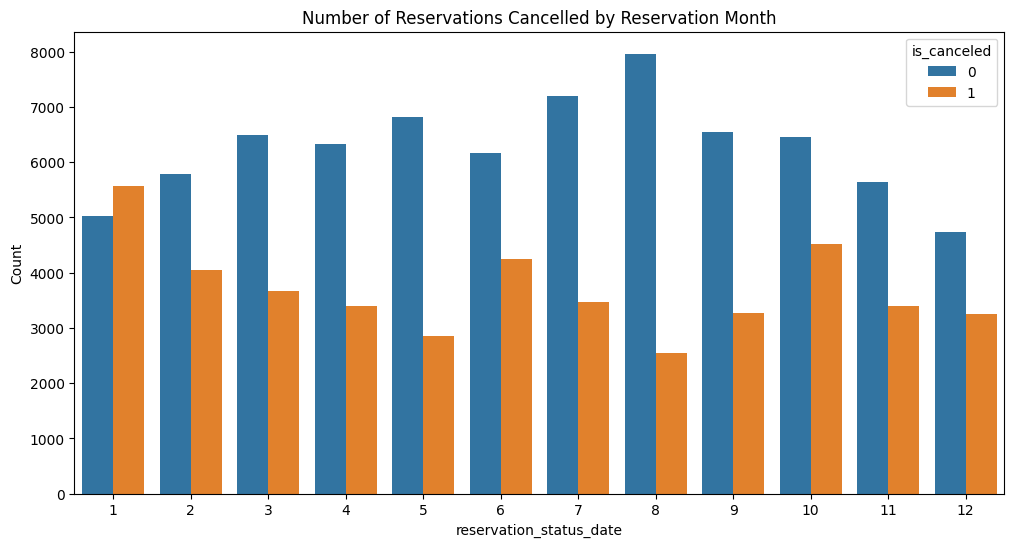

In [33]:
df["reservation_status_month"] = df["reservation_status_date"].dt.month
plt.figure(figsize=(12, 6))
sns.countplot(x='reservation_status_month', hue='is_canceled', data=df)
plt.title('Number of Reservations Cancelled by Reservation Month')
plt.xlabel('reservation_status_date')
plt.ylabel('Count')
plt.show()

In [34]:
df.groupby("reservation_status_month")["is_canceled"].mean()

,is_canceled
reservation_status_month,
1,0.525
2,0.411
3,0.362
4,0.349
5,0.295
6,0.408
7,0.325
8,0.242
9,0.333


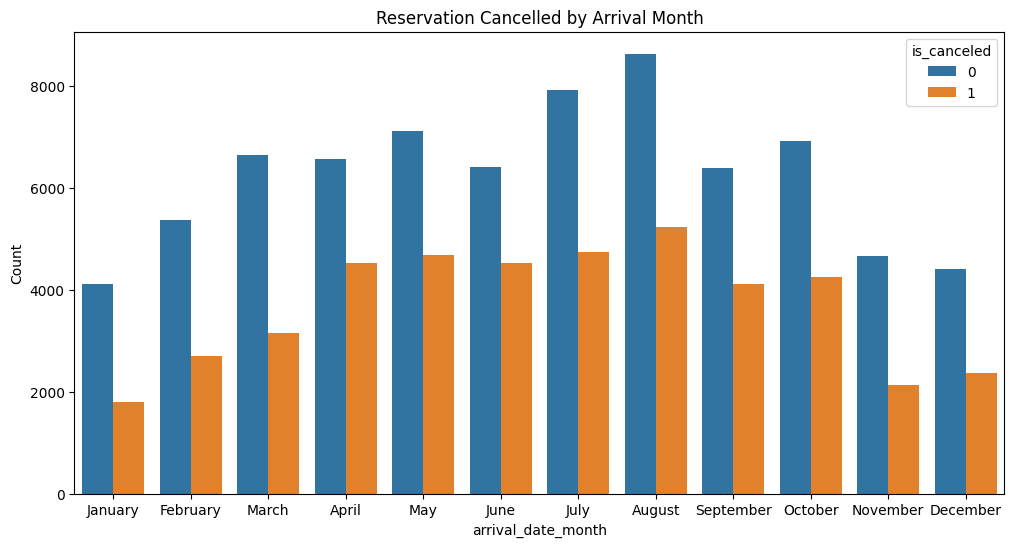

In [35]:
plt.figure(figsize=(12, 6))
sns.countplot(x='arrival_date_month', hue='is_canceled', data=df, order=['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'])
plt.title("Reservation Cancelled by Arrival Month")
plt.xlabel('arrival_date_month')
plt.ylabel('Count')
plt.show()

In [36]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
df.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order)

,is_canceled
arrival_date_month,
January,0.305
February,0.334
March,0.322
April,0.408
May,0.397
June,0.415
July,0.375
August,0.378
September,0.392


Looking at this distribution:
- The number of cancellations is high for reservations made in January, July, and October.
- The number of cancellations is high for reservations with a stay between April and July.

In terms of proportions:
- The number of cancellations is high for reservations made between October and March.
- The number of cancellations is high for stays between April and October.

Additionally, let's also examine the accomodation cost, which could be related to the stay month.

/tmp/ipykernel_1205/3958605066.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_avg = df.groupby('arrival_date_month')['adr'].mean()


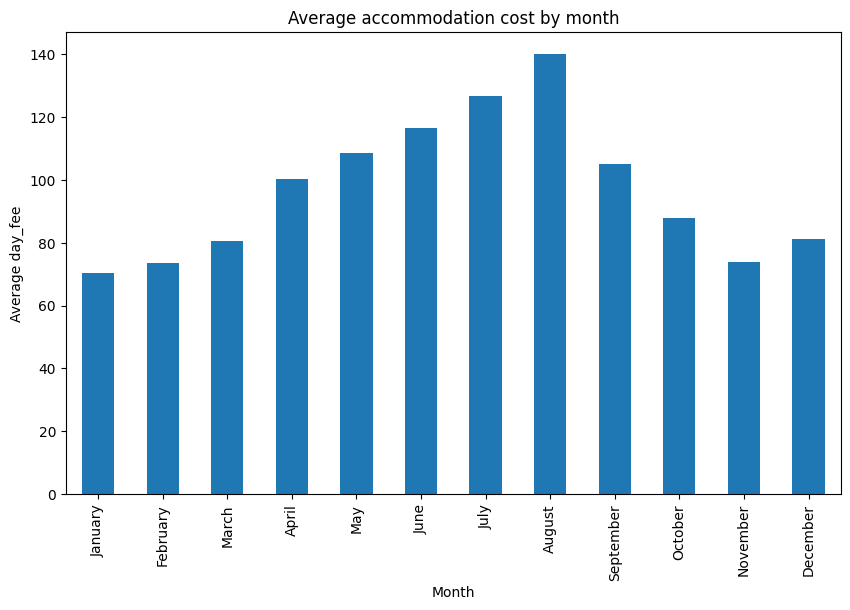

In [37]:
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

# Calculate the average day_fee for each month
monthly_avg = df.groupby('arrival_date_month')['adr'].mean()

# Plot the graph
fig, ax = plt.subplots(figsize=(10, 6))
monthly_avg.plot(kind='bar', ax=ax)

ax.set_xlabel('Month')
ax.set_ylabel('Average day_fee')
ax.set_title('Average accommodation cost by month')
plt.show()

The distribution of cancellations and accommodation costs by month apperas to be similar. Let's test if there's a significant correlation betweent them using the correlation coefficient.

The null hypothesis in this case is 'There is no correlation between cancellations and accommodation costs.' If the p-value is small, this hypothesis will be rejected, and it will be proven that there is a correlation."

In [38]:
new_df = df[["arrival_date_month",'adr', 'is_canceled']].groupby('arrival_date_month').mean()
corr_coef, p_value = stats.pearsonr(new_df['adr'], new_df['is_canceled'])
print(f'Correlation coefficient: {corr_coef:.3f}')
print(f'P-value: {p_value:.3f}')

Correlation coefficient: 0.720
P-value: 0.008


/tmp/ipykernel_1205/4272246903.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  new_df = df[["arrival_date_month",'adr', 'is_canceled']].groupby('arrival_date_month').mean()


Since the p-value is less than 0.01, the hypothesis of no correlation is rejected, and it can be concluded that there is a correlation between cancellations and accommodation costs by month.

However, simply making improvements based on this correlation between cancellations and `adr` is insufficient.

If there is no significant difference between `adr` for canceled bookings and `adr` for non-canceled bookings, approaching this variable may not be very useful.

In [39]:
t_statistic, p_value = stats.ttest_ind(df_cancel.groupby("arrival_date_month")["adr"].mean(), df.groupby("arrival_date_month")["adr"].mean())
print(f'T-statistic: {t_statistic:.2f}')
print(f'p-value: {p_value:.5f}')

T-statistic: 0.30
p-value: 0.76620


/tmp/ipykernel_1205/2579476183.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t_statistic, p_value = stats.ttest_ind(df_cancel.groupby("arrival_date_month")["adr"].mean(), df.groupby("arrival_date_month")["adr"].mean())


The p-value exceeds 0.01, so there is no significant difference.

While the accommodation cost seems to affect cancellations during the stay month, there is no significant difference in adr between canceled and non-canceled reservations. Thus, any interventions may have limited effectiveness.。

Let's look at the difference between the reservation date and the stay date. The ```lead_time``` column is suitable for checking this.

In [40]:
df_cancel = df[df["is_canceled"] == 1]
df_lead_month = pd.DataFrame()
df_lead_month["all"] = pd.Series(df.groupby("reservation_status_month")["lead_time"].mean())
df_lead_month["cancel"] = pd.Series(df_cancel.groupby("reservation_status_month")["lead_time"].mean())
df_lead_month

,all,cancel
reservation_status_month,,
1,110.029,160.621
2,85.290,132.844
3,90.288,129.537
4,99.321,140.413
5,100.210,120.582
6,118.334,146.830
7,108.130,122.576
8,99.352,122.031
9,110.539,143.585


There seems to be a difference between the overall values and the cancellations as well. Let's perform a t-test this time.

In [41]:
t_statistic, p_value = stats.ttest_ind(df_lead_month["all"],df_lead_month["cancel"])
print(f'T-statistic: {t_statistic:.2f}')
print(f'p-value: {p_value:.5f}')

T-statistic: -3.78
p-value: 0.00104


There was a significant difference in ```lead_time``` depending on whether the reservation was canceled or not. An approach focused on ```lead_time``` seems effective.

### 3-3. Creating a Model

We will create a predictive model with ```is_canceled``` as the target variable, conduct feature importance analysis, and connect the insights from previous exploratory data analysis (EDA) and market analysis to hypothesis formulation for possible actions.



For this machine learning model, we will use 28 columns excluding object-type data. The hyperparameters were tuned using Optuna.

In the actual final project, it is recommended to perform feature engineering by creating columns yourself, similar to a competition setting.

The following model achieved a very high accuracy with an AUC of 92%.

Additionally, we will explore the optimal threshold that best represents the data.

In [42]:
# Reload the data and excluse object-type data
df_train = pd.read_csv('Hotel-booking-demand-master/hotel_bookings.csv')
df_train = df_train.select_dtypes(exclude=['object'])

In [43]:
features = df_train.drop(columns=[
    'is_canceled',
    'arrival_date_year',
    'arrival_date_week_number',
    'arrival_date_day_of_month'
])
target = df_train['is_canceled']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

train_set = lgb.Dataset(X_train, y_train)
test_set = lgb.Dataset(X_test, y_test)

# Parameter settings

params = {'objective': 'binary',
 'metric': 'auc',
 'random_state': 42,
 'early_stopping_round': 10,
 'feature_pre_filter': False,
 'lambda_l1': 3.6220197651842656e-05,
 'lambda_l2': 0.0009871568791219231,
 'num_leaves': 251,
 'feature_fraction': 0.6799999999999999,
 'bagging_fraction': 1.0,
 'bagging_freq': 0,
 'min_child_samples': 5,
 'num_iterations': 1000}

# Training
model = lgb.train(
    params = params,
    train_set = train_set,
    valid_sets = [test_set],
)
y_pred = model.predict(X_test)  # Replace X_test with your test data
auc = roc_auc_score(y_test, y_pred)

print("AUC:", auc)

[LightGBM] [Info] Number of positive: 35253, number of negative: 60259
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011029 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1157
[LightGBM] [Info] Number of data points in the train set: 95512, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.369095 -> initscore=-0.536101
[LightGBM] [Info] Start training from score -0.536101
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[290]	valid_0's auc: 0.921893
AUC: 0.9218931648879389


In [44]:
# Search for the optimal threshold
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print("Optimal threshold:", optimal_threshold)

Optimal threshold: 0.35290912137011393


Let's also check which variables the model has considered important during training. In this model, it is clear that ```adr``` and ```lead_time``` are the most important variables. From the machine learning model's perspective, **we can conclude that focusing on ``lead_time`` is useful**.

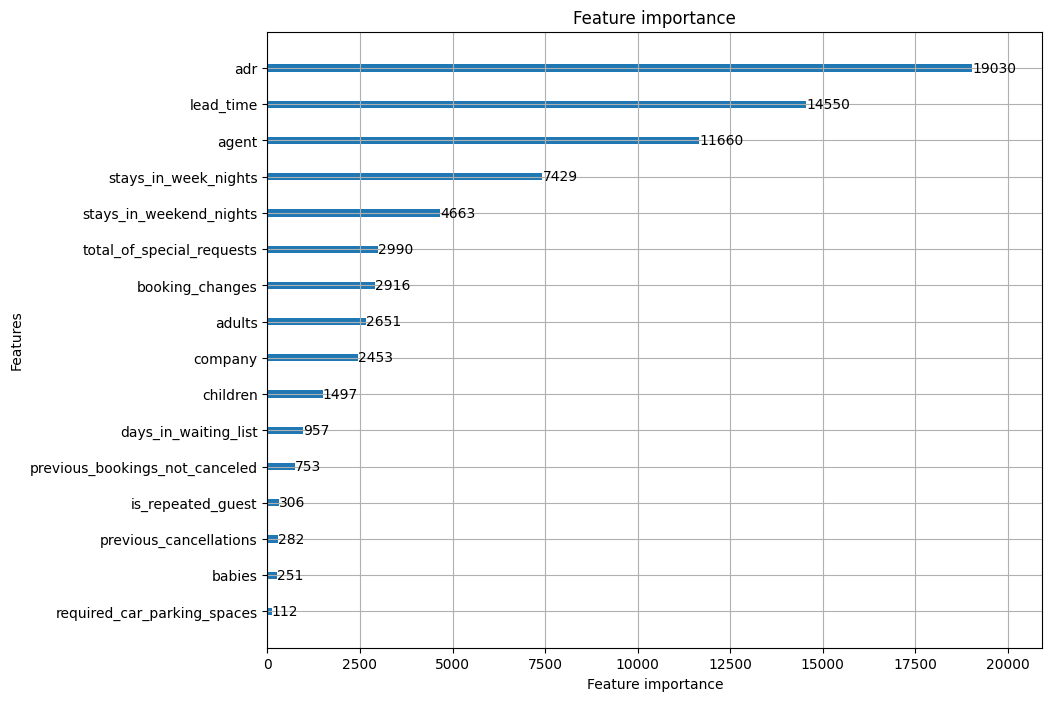

In [45]:
lgb.plot_importance(model, figsize=(10, 8))
plt.show()

## 4.Formulating the Business Proposal

What business proposals can be considered regarding ``lead_time``?

From the initial EDA, it was found that the larger the lead_time, the higher the likelihood of cancellation. In other words, reducing the number of days available for advance booking would likely lower the cancellation rate.


After examining ``lead_time`` further by month, it was found that the ``lead_time`` is over 40 days longer compared to the overall data from October to March, . Additionally, the EDA showed that the number of cancellations is higher for reservations made between October and March.

Therefore, the proposal is: "**For bookings made between October and March, reduce the number of available advance booking days. Specifically, shorten the range based on the ratio of the average cancellation lead time to the overall average lead time.**"

In this case, the proposal is to reduce the available advance booking days to about 70% of the current duration.

In [46]:
df.groupby("reservation_status_month")["is_canceled"].mean()

,is_canceled
reservation_status_month,
1,0.525
2,0.411
3,0.362
4,0.349
5,0.295
6,0.408
7,0.325
8,0.242
9,0.333


In [47]:
df_lead_month["cancel"]-df_lead_month["all"]

,0
reservation_status_month,
1,50.592
2,47.554
3,39.249
4,41.092
5,20.372
6,28.496
7,14.447
8,22.679
9,33.046


In [48]:
df['lead_time'].mean() / df_cancel['lead_time'].mean()

np.float64(0.7180688104227855)

## 5.Testing the Business Proposal

In [49]:
df_pred = pd.read_csv('Hotel-booking-demand-master/hotel_bookings.csv')
df_pred["reservation_status_month"] = pd.to_datetime(df_pred["reservation_status_date"]).dt.month
df_cancel = df_pred[df_pred["is_canceled"] == 1]
df_pred.loc[df_pred['reservation_status_month'].isin([1,2,3,10,11,12]), 'lead_time'] = df_pred['lead_time'] * (df['lead_time'].mean() / df_cancel['lead_time'].mean())
df_pred = df_pred.select_dtypes(exclude=['object'])

/tmp/ipykernel_1205/1419527415.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_pred["reservation_status_month"] = pd.to_datetime(df_pred["reservation_status_date"]).dt.month
/tmp/ipykernel_1205/1419527415.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[245.57953316 529.21671328   5.02648167 ...  45.23833506  45.23833506
  45.23833506]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_pred.loc[df_pred['reservation_status_month'].isin([1,2,3,10,11,12]), 'lead_time'] = df_pred['lead_time'] * (df['lead_time'].mean() / df_cancel['lead_time'].mean())


By performing this operation, a dataset representing the expected situation after the business proposal has been created.

By using this dataset and the cancellation prediction model, we can verify to what extent the cancellations have been reduced and assess the validity of the business proposal.

Let's check how the predicted cancellation numbers have changed by applying the threshold we obtained earlier.

In [50]:
df_pred = df_pred.select_dtypes(exclude=['object'])
features = df_pred.drop(columns=[ 'is_canceled',  'arrival_date_year',
       'arrival_date_week_number',
       'arrival_date_day_of_month','reservation_status_month'])
target = df_pred['is_canceled']

# Split the data into training and testi
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

new_y_pred = model.predict(X_test)  # Replace X_test with your test data

In [51]:
y_pred_binary = np.where(y_pred > optimal_threshold, 1, 0)
new_y_pred = np.where(new_y_pred > optimal_threshold, 1, 0)

In [52]:
print("Predicted cancellations before the business proposal")
print(pd.Series(y_pred_binary).value_counts())
print("Predicted cancellations after the business proposal")
print(pd.Series(new_y_pred).value_counts())
print("Number of cancellations improved after the business proposal")
print(pd.Series(y_pred_binary).value_counts()[1] - pd.Series(new_y_pred).value_counts()[1])


Predicted cancellations before the business proposal
0    14303
1     9575
Name: count, dtype: int64
Predicted cancellations after the business proposal
0    14514
1     9364
Name: count, dtype: int64
Number of cancellations improved after the business proposal
211


The model's prediction indicates an improvement of 205 cancellations. Since this is 20% of the total, it means that a total of 1,025 cancellations have been reduced. Moreover, this change is expected to result in an increase of 4.14 million yen in revenue.

In [53]:
print(df["adr"].mean() * 1025*39.63)  # PLN/JPY(2024/6/7)

4136456.5300711957


## 6.Conclusion

In this analysis, we used hotel reservation data to explore a business proposal aimed at improving cancellation rates and increasing revenue.
The key steps we covered in this notebook include:
1. **Exploratory Data Analysis (EDA):** We began by examining the dataset to understand its structure and trends.
2. **Market Analysis:** We performed market analysis to gain a deeper understanding of the problem at hand.
3. **Detailed EDA:** We then related different columns and conducted further EDA to investigate the specifics of the problem.
4.**Machine Learning Model:** We built a machine learning model and used it to quantitatively demonstrate the potential impact of our business proposal.




This notebook was created to help understand the outline of the final assignment, and there are the following improvements that could be made in the actual final assignment.

**Future Improvement Points：**
- In the market analysis, it is necessary to enhance credibility by referring to reliable sources, such as reports by government agencies, and presenting more documents.
- The business proposal focuses solely on the ``lead_time`` column. It might be a good idea to consider a more comprehensive analysis involving additional columns.
- The quantitative evaluation of the business proposal has been carried out, but it may lack creativity. It may be necessary to look for a more creative and effective proposal.
- The additional revenue was simply calculated based on the number of cancellations and the average spending amount, but in reality, many more factors could affect the result. Taking those into consideration can add more quantitative credibility.

Additionally, in reality, the potential loss caused by a decrease in the number of reservations due to shortening the booking window must also be considered.